# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/egeklc/flyrank-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

# Abstract
This project develops a machine-learning approach to rank content pages by their likelihood of declining performance, helping SEO teams prioritize pages for review. A Random Forest model is compared with a rule-based baseline using a client-grouped holdout split to evaluate performance on unseen clients. The Random Forest achieved a Precision@50 of 0.680 and ROC-AUC of 0.600, outperforming the baseline on both metrics. Of the 50 highest-ranked pages, 34 were labeled as declining, compared with 25 for the baseline model. The resulting ranked queue includes reason codes and suggested actions to support human review, although further evaluation is needed to assess its effectiveness across different datasets and future periods.

## 1. Question

*The research question and the decision it supports.*

**Research Question:** Can a machine-learning model rank content pages by their likelihood of declining performance to help an SEO team prioritize which pages to review first for content refresh?

  
**Decision Supported:** The model produces a ranked review queue to help the SEO team prioritize which pages to review first. It also provides reason codes and action recommendations that can help the SEO team investigate potential performance issues, while the final decision remains with a human reviewer.

In [1]:
!git clone https://github.com/egeklc/flyrank-internship.git

import os
import pandas as pd
os.chdir("flyrank-internship")
print(os.getcwd())

df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
df["is_declining"] = df["trend_direction"].str.lower().eq("down").astype(int)

fatal: destination path 'flyrank-internship' already exists and is not an empty directory.
/content/flyrank-internship


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

This capstone uses FlyRank ML Intership Starter dataset (`content_refresh_anonymized.csv`). The dataset contains 30,000 rows and 44 columns across 32 pseudonymized clients. Each row represents a content page with performance metrics and content attributes.

In [2]:
print("Total pages: ", len(df))
print("Total clients: ", df["client_id"].nunique())

Total pages:  30000
Total clients:  32


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

The binary target, `is_declining`, is derived from `trend_direction`: pages labeled "down" receive 1, and all other values receive 0.

**Feature exclusions:** `trend_direction` and `trend_pct` are excluded to prevent direct use of trend information. `is_declining` is excluded from the predictors because it is the target. The six last-30-day and previous-30-day impressions, clicks, and sessions columns are also excluded to reduce leakage risk.

**Identifier handling:** `content_id` and `client_id` are pseudonyms used for identification, joins, and validation not model features. `client_id` is retained separately for grouped train/test splitting, ensuring that test clients are unseen during training.

The model uses the remaining eligible numerical and categorical features to rank pages by their likelihood of declining performance.

**Baseline Model:** A rule-based score combines content staleness (at least 91 days since update), visibility (at least 500 impressions over 90 days), and the non-negative gap between expected and actual CTR. The score weights this gap by normalized impressions and staleness.

**Models and validation:** The Random Forest model is evaluated against the baseline. A client-grouped holdout split ensures that no client appears in both training and test sets, measuring generalization to unseen clients. Precision@50 measures the proportion of labeled-declining pages among the 50 highest-ranked pages, with both methods evaluated on the same test set.

In [3]:
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score



target_col = "is_declining"
group_col = "client_id"

excluded_cols = ['content_id', 'client_id',
                 "trend_direction", "trend_pct", "is_declining",
                 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'impressions_prev_30d',
                 'clicks_prev_30d', 'sessions_prev_30d'
                 ]

num_cols = [col for col in df.select_dtypes(include=["int64", "float64"]).columns
            if col not in excluded_cols
            ]

cat_cols = [col for col in df.select_dtypes(include=["object"]).columns
            if col not in excluded_cols
            ]

feature_cols = num_cols + cat_cols
model_df = df[feature_cols + [target_col, group_col]].copy()

## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

The baseline and Random Forest were evaluated on the same client-grouped holdout test set. The Random Forest achieved higher Precision@50 and ROC-AUC than the rule-based baseline. Precision@50 increased from 0.500 to 0.680, meaning that 34 of the Random Forest's top 50 pages were labeled as declining, compared with 25 for the baseline. The Random Forest's Precision@50 was 16.3 points higher than the overall decline-label rate in the test set (51.7%). ROC-AUC increased from 0.504 to 0.600, indicating improved discrimination between pages labeled as declining and those not labeled as declining on this holdout set. These results show that the Random Forest ranked labeled-declining pages more effectively than the baseline in this evaluation, but do not establish how well it will perform on other datasets or future periods.

In [4]:
def build_random_forest_model(num_cols, cat_cols):

    numeric_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value=0))
    ])
    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    preprocessor = ColumnTransformer([
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=20,
            min_samples_split=15,
            min_samples_leaf=8,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
    return model

def precision_at_k(y_true, scores, k=50):
    order = np.argsort(scores)[::-1]
    top_k = order[:k]
    return y_true.iloc[top_k].mean()

gss = GroupShuffleSplit(n_splits=1, test_size = 0.25, random_state=42)
train_idx, test_idx = next(gss.split(model_df, groups=model_df[group_col]))

train_df = model_df.iloc[train_idx].copy()
test_df = model_df.iloc[test_idx].copy()

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]


train_clients = set(train_df[group_col])
test_clients = set(test_df[group_col])

print(f"Training rows: {len(train_df)}")
print(f"Test rows: {len(test_df)}")
print(f"Training clients: {len(train_clients)}")
print(f"Test clients: {len(test_clients)}")
print(f"Overlapping clients: {len(train_clients & test_clients)}")

Training rows: 22885
Test rows: 7115
Training clients: 24
Test clients: 8
Overlapping clients: 0


In [5]:
## RANDOM FOREST MODEL
rf = build_random_forest_model(num_cols, cat_cols)

rf.fit(X_train, y_train)
rf_scores = rf.predict_proba(X_test)[:, 1]

p_at_50 = precision_at_k(y_test, rf_scores, k=50)
rf_auc = roc_auc_score(y_test, rf_scores)

## BASELINE MODEL
volume_floor_train = train_df[(train_df["avg_position"] > 0) & (train_df["impressions_90d"] >= 500)]

expected_ctr_train = (volume_floor_train.groupby("position_tier")["ctr"].median())

max_impressions = train_df["impressions_90d"].max()

baseline_test = test_df.copy()
baseline_test["expected_ctr"] = (baseline_test["position_tier"].map(expected_ctr_train))
baseline_test["ctr_gap"] = (baseline_test["expected_ctr"] - baseline_test["ctr"]).clip(lower=0)
baseline_test.loc[baseline_test["avg_position"] <= 0, "ctr_gap"] = 0
baseline_test["stale"] = (baseline_test["days_since_last_update"] >= 91).astype(int)
baseline_scores = (baseline_test["stale"]* (baseline_test["impressions_90d"] / max_impressions)* baseline_test["ctr_gap"].fillna(0))

baseline_p_at_50 = precision_at_k(y_test, baseline_scores, k=50)
baseline_auc = roc_auc_score(y_test, baseline_scores)

print(f"Baseline Precision@50: {baseline_p_at_50:.3f}")
print(f"Baseline ROC-AUC: {baseline_auc:.3f}")

print(f"Random Forest Precision@50: {p_at_50:.3f}")
print(f"Random Forest ROC-AUC: {rf_auc:.3f}")

results = pd.DataFrame({
    "Metric": ["Precision@50", "Precision@50", "ROC-AUC", "ROC-AUC"],
    "Model": ["Baseline", "Random Forest", "Baseline", "Random Forest"],
    "Score": [baseline_p_at_50, p_at_50, baseline_auc, rf_auc]
})

decline_rate = y_test.mean()
non_decline_rate = 1 - decline_rate

print("\n--- Test-Set Decline Label Distribution ---")
print(f"Total pages in test set: {len(y_test)}")
print(f"Pages labeled as declining: {(y_test == 1).sum()}")
print(f"Pages not labeled as declining: {(y_test == 0).sum()}")
print(f"Decline-label rate: {decline_rate:.1%}")
print(f"Non-decline label rate: {non_decline_rate:.1%}")

Baseline Precision@50: 0.500
Baseline ROC-AUC: 0.504
Random Forest Precision@50: 0.680
Random Forest ROC-AUC: 0.600

--- Test-Set Decline Label Distribution ---
Total pages in test set: 7115
Pages labeled as declining: 3675
Pages not labeled as declining: 3440
Decline-label rate: 51.7%
Non-decline label rate: 48.3%


In [6]:
ranking_eval = pd.DataFrame({
    "content_id": df.iloc[test_idx]["content_id"].to_numpy(),
    "is_declining": y_test.to_numpy(),
    "rf_score": rf_scores
})

ranking_eval = (
    ranking_eval
    .sort_values("rf_score", ascending=False)
    .reset_index(drop=True)
)

top_50_eval = ranking_eval.head(50).copy()

top_50_positive = (top_50_eval["is_declining"] == 1).sum()
top_50_negative = (top_50_eval["is_declining"] == 0).sum()

top_50_precision = (
    top_50_positive / len(top_50_eval)
    if len(top_50_eval) > 0 else np.nan
)

print("\n--- Random Forest: Top-50 Evaluation ---")
print(f"Pages labeled as declining in top 50: {top_50_positive}")
print(f"Pages not labeled as declining in top 50: {top_50_negative}")
print(f"Random Forest Precision@50: {top_50_precision:.3f}")
print(f"Test-set decline-label rate: {decline_rate:.1%}")
print(
    "Random Forest Precision@50 above test-set decline rate: "
    f"{(top_50_precision - decline_rate) * 100:+.1f} percentage points"
)


--- Random Forest: Top-50 Evaluation ---
Pages labeled as declining in top 50: 34
Pages not labeled as declining in top 50: 16
Random Forest Precision@50: 0.680
Test-set decline-label rate: 51.7%
Random Forest Precision@50 above test-set decline rate: +16.3 percentage points


## 5. Limitations

*What this work cannot claim.*

* Prediction is not causation: A high model score indicates a higher predicted likelihood of decline, not that a page will continue declining or that refreshing it will improve performance.

* Limited generalization: The client-grouped holdout tests performance on unseen clients within this dataset. It does not guarantee performance across other SEO datasets, industries, or future periods.

* Limited dataset coverage: The dataset contains 30,000 content pages from 32 pseudonymized clients. Results may not represent the wider population of websites or content types.

* Baseline and model evaluation: The Random Forest outperformed the rule-based baseline on the same holdout set, but this comparison alone does not establish that the model will deliver better business outcomes.

* Human review remains necessary: Reason codes and suggested actions support investigation; they do not establish the cause of declining performance or automatically determine whether a page should be refreshed, expanded, protected, or monitored.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

In [7]:
visible_train = train_df[
    train_df["impressions_90d"] >= 500
]

word_count_threshold = visible_train["word_count"].quantile(0.25)


def get_reason_action_codes(row):
    if row["stale"] and row["visible"] and row["ctr_gap"] > 0:
        return "stale_visible_low_ctr", "review_content_and_search_performance"

    elif row["stale"] and row["visible"]:
        return "stale_visible_page", "review_content_freshness"

    elif (
        row["ctr_gap"] > 0
        and row["position_tier"] in ["top_3", "page_1", "striking"]
    ):
        return "low_ctr_for_position", "review_search_performance"

    elif row["position_tier"] in ["page_3_5", "deep"]:
        return "low_visibility", "review_search_visibility"

    elif row["visible"] and row["word_count"] <= word_count_threshold:
        return "thin_visible_page", "review_content_depth"

    else:
        return "no_strong_signal", "monitor_page"



ranked_test = df.iloc[test_idx].copy().reset_index(drop=True)
ranked_test["rf_score"] = rf_scores
ranked_test["visible"] = (ranked_test["impressions_90d"] >= 500).astype(int)
ranked_test["stale"] = (ranked_test["days_since_last_update"] >= 91).astype(int)
ranked_test["expected_ctr"] = (ranked_test["position_tier"].map(expected_ctr_train))
ranked_test["ctr_gap"] = (ranked_test["expected_ctr"] - ranked_test["ctr"]).clip(lower=0)
ranked_test.loc[ranked_test["avg_position"] <= 0,"ctr_gap"] = 0
ranked_test["ctr_gap"] = ranked_test["ctr_gap"].fillna(0)
ranked_test[["reason_code", "action_code"]] = ranked_test.apply(get_reason_action_codes,
                                                                axis=1,
                                                                result_type="expand"
                                                                )

ranked_test = (ranked_test.sort_values("rf_score", ascending=False).reset_index(drop=True))
ranked_test["rank"] = ranked_test.index + 1
action_queue = ranked_test[
    [
        "rank",
        "content_id",
        "rf_score",
        "reason_code",
        "action_code"
    ]
].copy()

top_50_reason = action_queue[["reason_code"]].head(50).value_counts()
print("\nReason code distribution across the top 50 ranked pages:\n", top_50_reason.to_string())


Reason code distribution across the top 50 ranked pages:
 reason_code          
stale_visible_low_ctr    21
low_ctr_for_position     19
stale_visible_page       10


In [8]:
display(action_queue.head(50))

,rank,content_id,rf_score,reason_code,action_code
0,1,content_2ba626fea4d6,0.949247,low_ctr_for_position,review_search_performance
1,2,content_e988c1699454,0.937012,stale_visible_low_ctr,review_content_and_search_performance
2,3,content_569475b335ab,0.922198,stale_visible_page,review_content_freshness
3,4,content_bb1edbf0ba6c,0.919305,stale_visible_low_ctr,review_content_and_search_performance
4,5,content_9ac61c04930e,0.918642,stale_visible_low_ctr,review_content_and_search_performance
5,6,content_8f1409b2674e,0.916716,low_ctr_for_position,review_search_performance
6,7,content_41baf0722ad9,0.912858,stale_visible_low_ctr,review_content_and_search_performance
7,8,content_6607847e4454,0.912646,stale_visible_low_ctr,review_content_and_search_performance
8,9,content_500bd3907331,0.911201,stale_visible_low_ctr,review_content_and_search_performance
9,10,content_b46c62b14582,0.909224,stale_visible_page,review_content_freshness


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

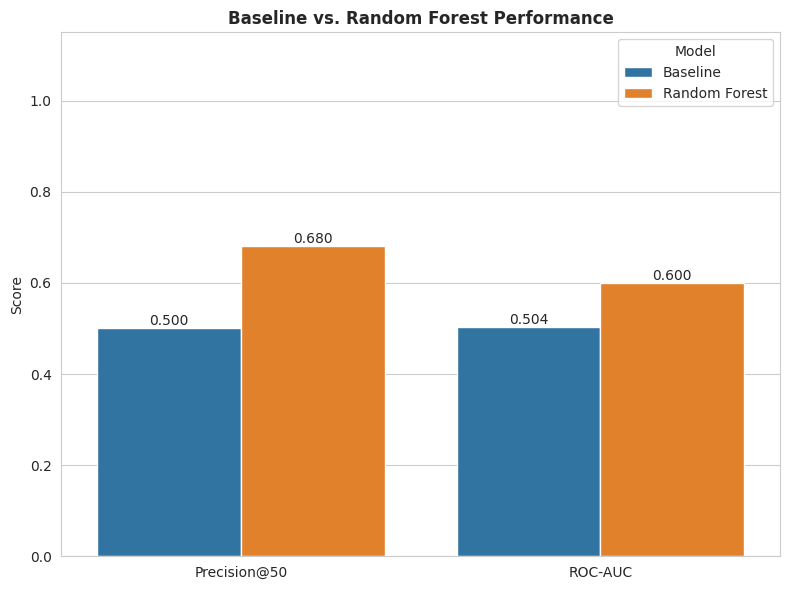

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

fig_path = "work/figures/"
os.makedirs(fig_path, exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=results, x="Metric", y="Score", hue="Model", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f")
ax.set_title("Baseline vs. Random Forest Performance", fontweight="bold")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.15)
ax.legend(title="Model")
plt.tight_layout()
fig.savefig(os.path.join(fig_path, "baseline_vs_random_forest.png"),
            dpi=300, bbox_inches="tight")
plt.show()

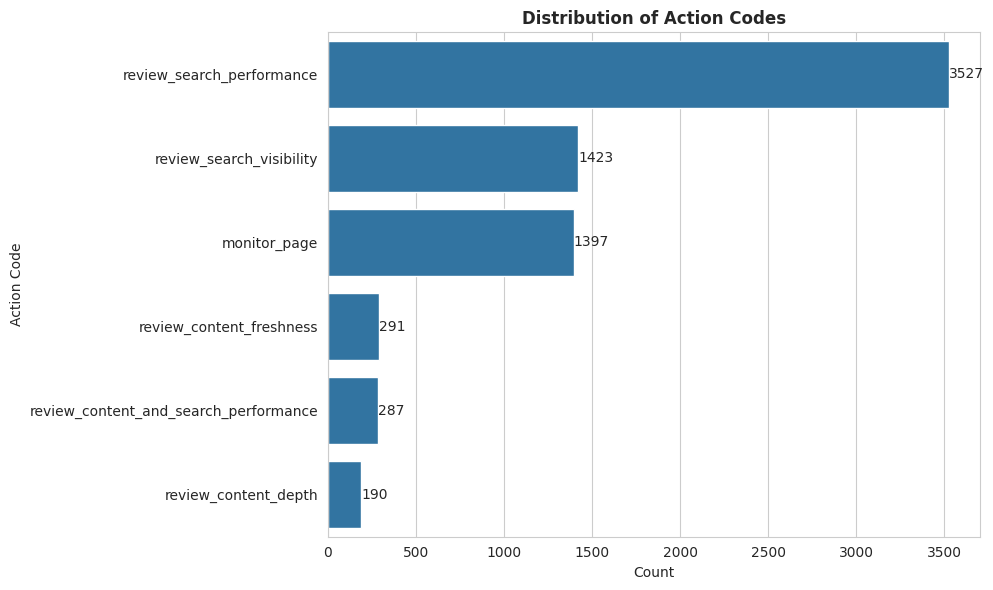

In [10]:
order = action_queue["action_code"].value_counts().index

fig, ax = plt.subplots(figsize=(10,6))
ax = sns.countplot(y=action_queue["action_code"], order=order)
ax.bar_label(ax.containers[0])
ax.set_title("Distribution of Action Codes", fontweight="bold")
ax.set_xlabel("Count")
ax.set_ylabel("Action Code")
plt.tight_layout()
fig.savefig(os.path.join(fig_path, "action_code_distribution.png"),
            dpi=300, bbox_inches="tight")
plt.show()

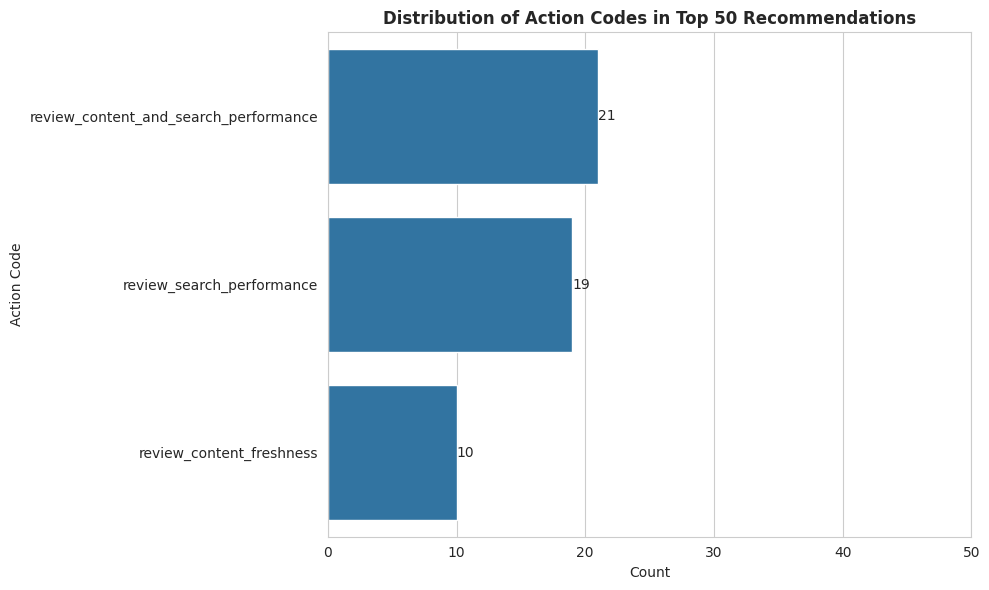

In [11]:
top50_action_queue = action_queue.head(50).copy()

fig, ax = plt.subplots(figsize=(10, 6))
order = top50_action_queue["action_code"].value_counts().index
ax = sns.countplot(data=top50_action_queue, y="action_code", order=order, ax=ax)
ax.bar_label(ax.containers[0])
ax.set_title("Distribution of Action Codes in Top 50 Recommendations", fontweight="bold")
ax.set_xlabel("Count")
ax.set_ylabel("Action Code")
ax.set_xlim(0, 50)
plt.tight_layout()
fig.savefig(os.path.join(fig_path, "top50_action_code_distribution.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# 5-minute Demo Outline
1. Problem
2. Dataset & Methodology
3. Model Results
4. Recommendations
5. Conclusion

## Social Media Post
I built a machine-learning project to help SEO teams prioritize content pages for review based on their likelihood of declining performance. I compared a Random Forest model with a rule-based baseline using a client-grouped holdout split. The Random Forest achieved 0.680 Precision@50 and 0.600 ROC-AUC, outperforming the baseline on both metrics. Of the 50 highest-ranked pages, 34 were labeled as declining. The project also includes a ranked review queue with reason codes and suggested actions to support human decision-making. Through this project, I explored practical applications of machine learning, model evaluation, validation design, and translating predictive results into actionable workflows.

## Employer-Facing Summary

Developed a machine-learning content-ranking system to help SEO teams prioritize pages for performance review. Built and evaluated a Random Forest model against a rule-based baseline using client-grouped validation, achieving 0.680 Precision@50 and 0.600 ROC-AUC, compared with 0.500 and 0.504 for the baseline. In the top 50 ranked pages, 34 were labeled as declining. Created a ranked review queue with reason codes and suggested actions to support human-led decisions. The project demonstrates practical skills in Python, scikit-learn, model evaluation, validation design, and translating predictive results into actionable workflows.


# Acknowledgments & Data Credit
This project was completed as part of the FlyRank ML Internship and was built on the FlyRank ML Internship dataset.

Data source: [FlyRank](https://flyrank.ai)



## Self-check

Before you submit, confirm each line honestly:

- [+] Every section above is filled — markdown thinking AND the code that backs it
- [+] The notebook runs top to bottom with no errors (Runtime → Run all)
- [+] No client names, URLs, or private queries anywhere
- [+] My claims use careful words: observed, measured, directional, decision-support
- [+] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [+] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [+] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
